**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

*   NOMBRE: Gael Isaac Jurado Romero
*   MATRÍCULA: A01841366

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Instalar las bibliotecas necesarias
!pip install category_encoders

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
url = "https://raw.githubusercontent.com/GJ030/Ciencia_datos/main/6.2%20Actividad%206%20-%20FE/computer_prices.csv"
compu_df = pd.read_csv(url)
compu_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  object 
 12  gpu_model            100000 non-null  object 
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb            

In [4]:
compu_df.nunique()

device_type                2
brand                     10
model                  99036
release_year               8
os                         4
form_factor               10
cpu_brand                  3
cpu_model              26971
cpu_tier                   6
cpu_cores                 12
cpu_threads               25
gpu_brand                  4
gpu_model                 49
gpu_tier                   6
vram_gb                    8
ram_gb                    15
storage_type               4
storage_gb                 5
storage_drive_count        4
display_type               6
charger_watts              7
psu_watts                  9
wifi                       4
bluetooth                  5
weight_kg                 47
warranty_months            4
price                   3366
dtype: int64

In [5]:
compu_df = compu_df.drop(columns=["model", "cpu_model"])

**Respuesta 1.** Según `info()` hay **15 columnas numéricas** (12 `int64` y 3 `float64`) y **12 columnas de texto** (`object`). Se eliminaron `model` y `cpu_model` porque, con 100000 registros, casi cada fila tiene un valor distinto y no sirven como variables predictoras.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

In [6]:
print("Registros duplicados:", compu_df.duplicated().sum())
print("Valores faltantes:", compu_df.isna().sum().sum())

Registros duplicados: 0
Valores faltantes: 0


In [7]:
num_cols = compu_df.select_dtypes(include="number").columns
compu_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


In [8]:
cat_cols = compu_df.select_dtypes(exclude="number").columns
compu_df[cat_cols].describe().T

,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


In [9]:
for col in cat_cols:
    print(compu_df[col].value_counts(), "\n")

device_type
Laptop     59844
Desktop    40156
Name: count, dtype: int64 

brand
Lenovo      15992
HP          14114
Dell        14005
Apple       11915
ASUS        10159
Acer         9925
Samsung      8066
MSI          7891
Gigabyte     4900
Razer        3033
Name: count, dtype: int64 

os
Windows     71817
macOS       18207
Linux        6109
ChromeOS     3867
Name: count, dtype: int64 

form_factor
Mainstream     17819
Gaming         16876
ATX            15597
Ultrabook      13236
Micro-ATX       8672
Full-Tower      7110
2-in-1          7049
SFF             5585
Workstation     4864
Mini-ITX        3192
Name: count, dtype: int64 

cpu_brand
Intel    52774
AMD      35311
Apple    11915
Name: count, dtype: int64 

gpu_brand
NVIDIA    54712
Apple     18922
AMD       15767
Intel     10599
Name: count, dtype: int64 

gpu_model
Apple Integrated    18922
RTX 40 70            5743
RTX 30 70            5692
RTX 40 60            5437
RTX 30 60            5314
RTX 30 50            5046
RTX 40 5

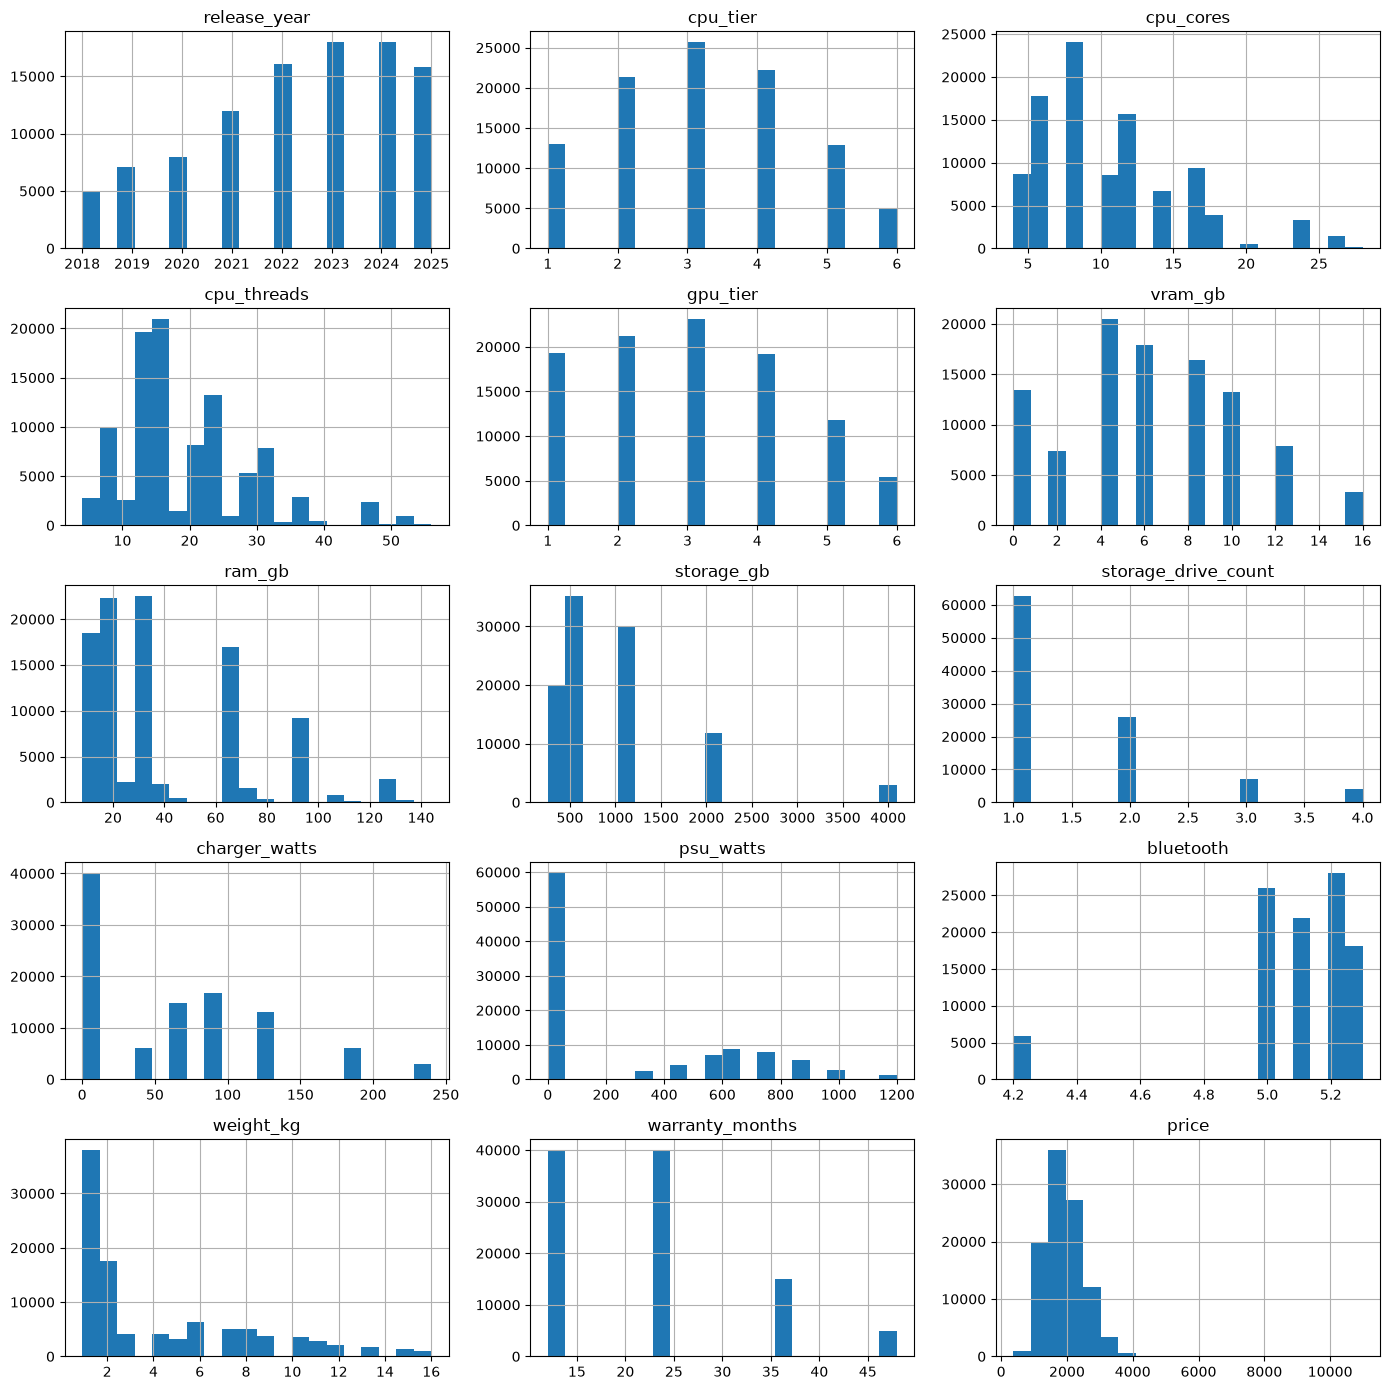

In [10]:
compu_df[num_cols].hist(bins=20, layout=(5, 3), figsize=(14, 14))
plt.tight_layout()
plt.show()

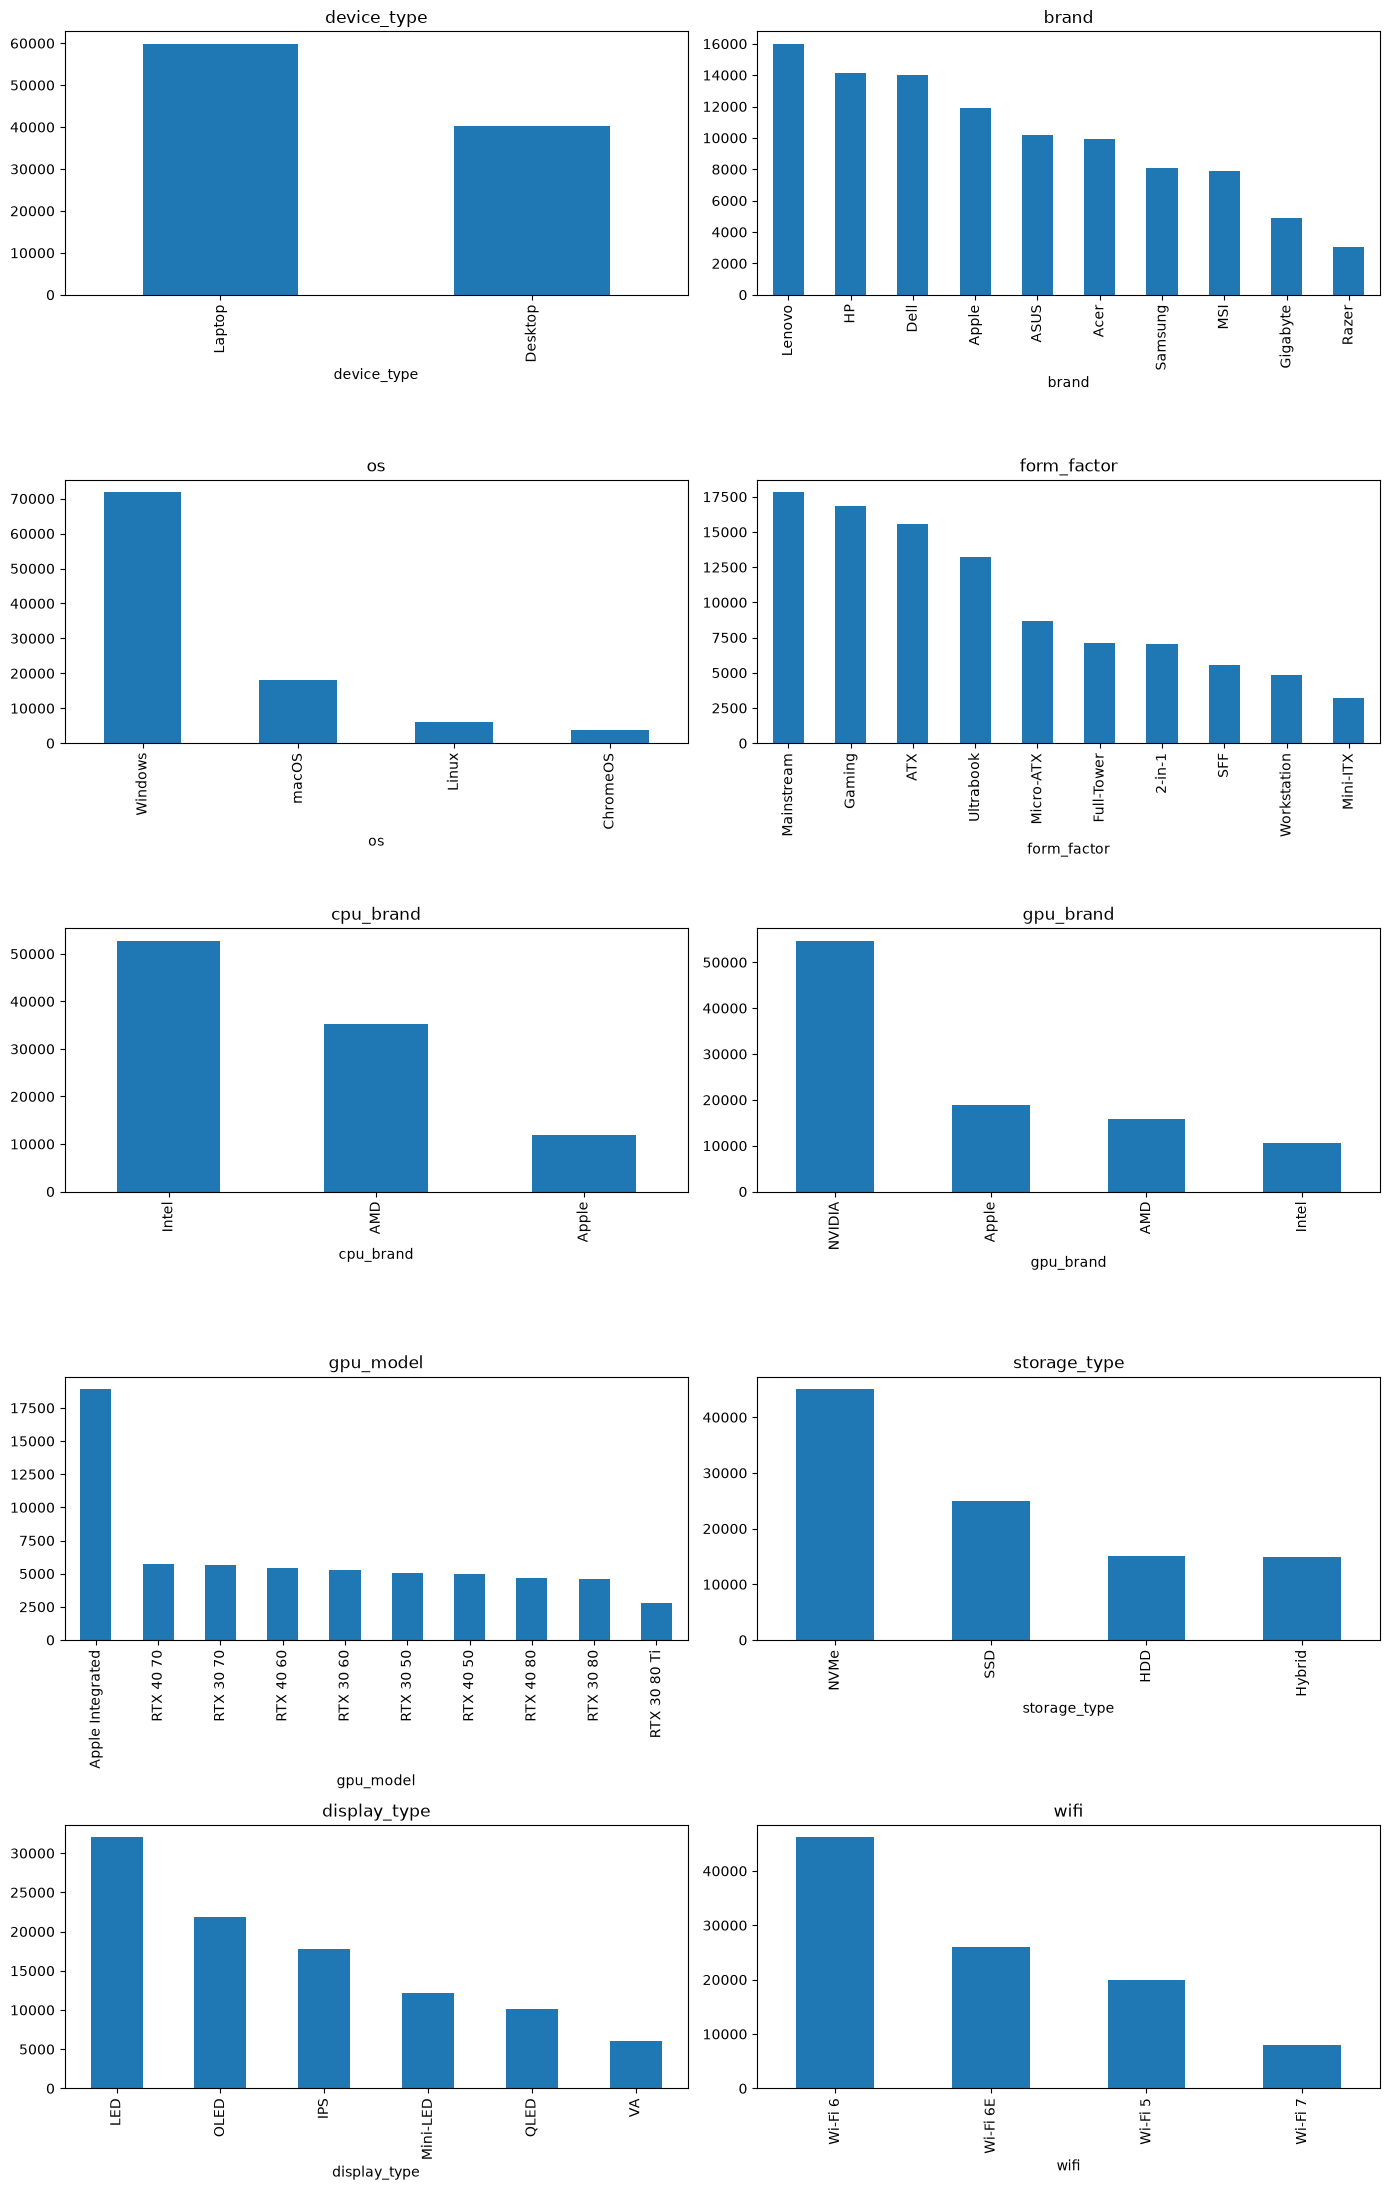

In [11]:
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for ax, col in zip(axes.ravel(), cat_cols):
    compu_df[col].value_counts().head(10).plot.bar(ax=ax, title=col)
plt.tight_layout()
plt.show()

**Respuesta 2.** No hay registros duplicados ni valores faltantes. En las numéricas, `price` y `weight_kg` tienen sesgo a la derecha (en `price` la media es 1928.76, mayor que la mediana de 1863.99, y el máximo es 10984.99 frente a un percentil 75 de 2287.99), y `charger_watts` y `psu_watts` tienen una barra muy alta en 0. En las categóricas predominan las laptops (59844 contra 40156 desktops), Windows (71817), Intel (52774) y NVIDIA (54712); `gpu_model` tiene 49 categorías, por eso su gráfico muestra solo las 10 más frecuentes (la primera es Apple Integrated, con 18922).

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

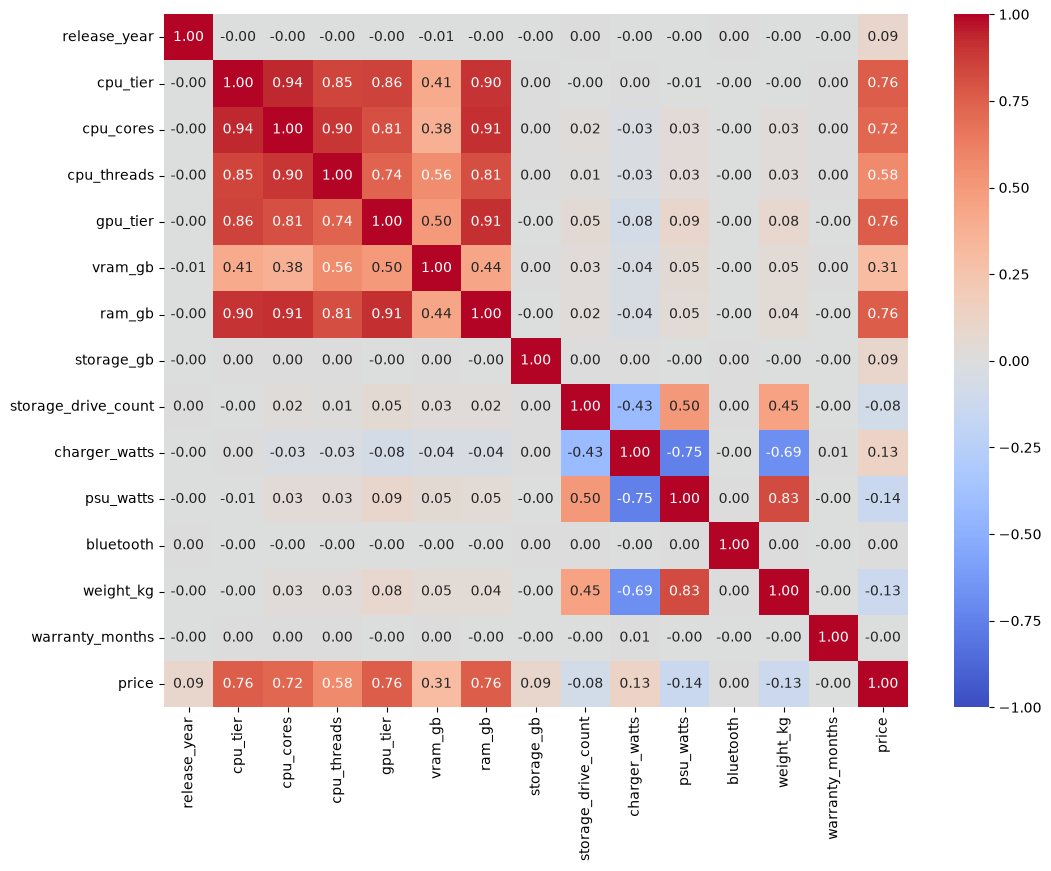

In [12]:
corr = compu_df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [13]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.9])

cpu_tier   cpu_cores    0.937376
cpu_cores  ram_gb       0.906770
gpu_tier   ram_gb       0.912918
dtype: float64


In [14]:
compu_df = compu_df.drop(columns=["cpu_cores", "ram_gb"])

**Respuesta 3.** Los pares con correlación mayor a 0.9 son `cpu_tier`-`cpu_cores` (0.937), `cpu_cores`-`ram_gb` (0.907) y `gpu_tier`-`ram_gb` (0.913). Se **conservaron `cpu_tier` y `gpu_tier`** porque resumen el desempeño general del procesador y de la tarjeta gráfica en una misma escala ordinal del 1 al 6, y se **eliminaron `cpu_cores` y `ram_gb`**, que son especificaciones puntuales que los niveles ya explican: con ambas fuera desaparecen los tres pares, y la información de núcleos sigue en `cpu_threads`. Según el mapa de calor, esta decisión no sacrifica relación con el objetivo: `cpu_tier`, `gpu_tier` y `ram_gb` tienen la misma correlación con `price` (0.76) y `cpu_cores` es la más baja de las cuatro (0.72).

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

In [15]:
compu_transf = compu_df.copy()
compu_transf["years_since_release"] = date.today().year - compu_transf["release_year"]
compu_transf = compu_transf.drop(columns="release_year")

Límites de los bins: [ 0.  4.  6.  8. 16.]


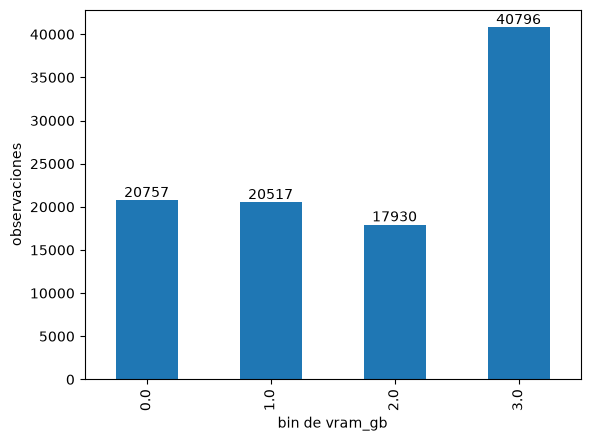

In [16]:
kbd = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile")
compu_transf[["vram_gb"]] = kbd.fit_transform(compu_transf[["vram_gb"]])
print("Límites de los bins:", kbd.bin_edges_[0])

ax = compu_transf["vram_gb"].value_counts().sort_index().plot.bar(xlabel="bin de vram_gb", ylabel="observaciones")
ax.bar_label(ax.containers[0])
plt.show()

**Respuesta 4.** `years_since_release` se calculó como el año en curso (`date.today().year`) menos `release_year`, y la columna original se eliminó. `KBinsDiscretizer` dejó los límites de los bins en 0, 4, 6, 8 y 16 GB, es decir, bin 0 = [0, 4) (20757 observaciones, valores de 0 y 2 GB), bin 1 = [4, 6) (20517, 4 GB), bin 2 = [6, 8) (17930, 6 GB) y bin 3 = [8, 16] (40796). Los bins no tienen el mismo tamaño porque `vram_gb` toma pocos valores discretos y los cuantiles caen sobre ellos: el 8 pasa al último bin junto con 10, 12 y 16 GB, que quedó con entre dos y 2.3 veces más observaciones que los demás.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

In [17]:
(compu_df[["charger_watts", "psu_watts"]] == 0).groupby(compu_df["device_type"]).sum()

,charger_watts,psu_watts
device_type,,
Desktop,40156,0
Laptop,0,59844


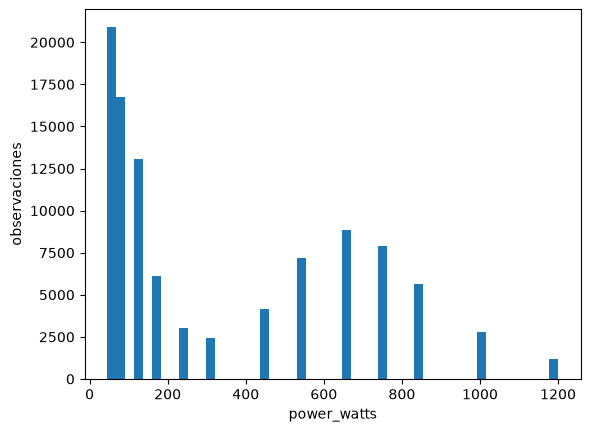

In [18]:
compu_transf["power_watts"] = compu_transf["charger_watts"] + compu_transf["psu_watts"]

plt.hist(compu_transf["power_watts"], bins=50)
plt.xlabel("power_watts")
plt.ylabel("observaciones")
plt.show()

compu_transf = compu_transf.drop(columns=["charger_watts", "psu_watts"])

**Respuesta 5.** El 0 no es una medición faltante, sino un "no aplica": las laptops usan cargador pero no tienen fuente de poder (`psu_watts` = 0 en las 59844 laptops) y los desktops usan fuente de poder pero no cargador (`charger_watts` = 0 en los 40156 desktops). Como cada dispositivo tiene una sola de las dos potencias, `power_watts` es su suma. Su histograma es **bimodal**: un grupo concentrado en valores bajos (cargadores de laptops, hasta 240 W) y otro en valores altos con pico cerca de 650 W (fuentes de poder de desktops, hasta 1200 W).

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

In [19]:
log_tr = FunctionTransformer(np.log)
sqrt_tr = FunctionTransformer(np.sqrt)
boxcox_tr = PowerTransformer(method="box-cox", standardize=False)

price = compu_transf[["price"]]
price_versions = {
    "Original": price["price"].to_numpy(),
    "Logaritmo": np.ravel(log_tr.fit_transform(price)),
    "Raíz cuadrada": np.ravel(sqrt_tr.fit_transform(price)),
    "Box-Cox": np.ravel(boxcox_tr.fit_transform(price)),
}

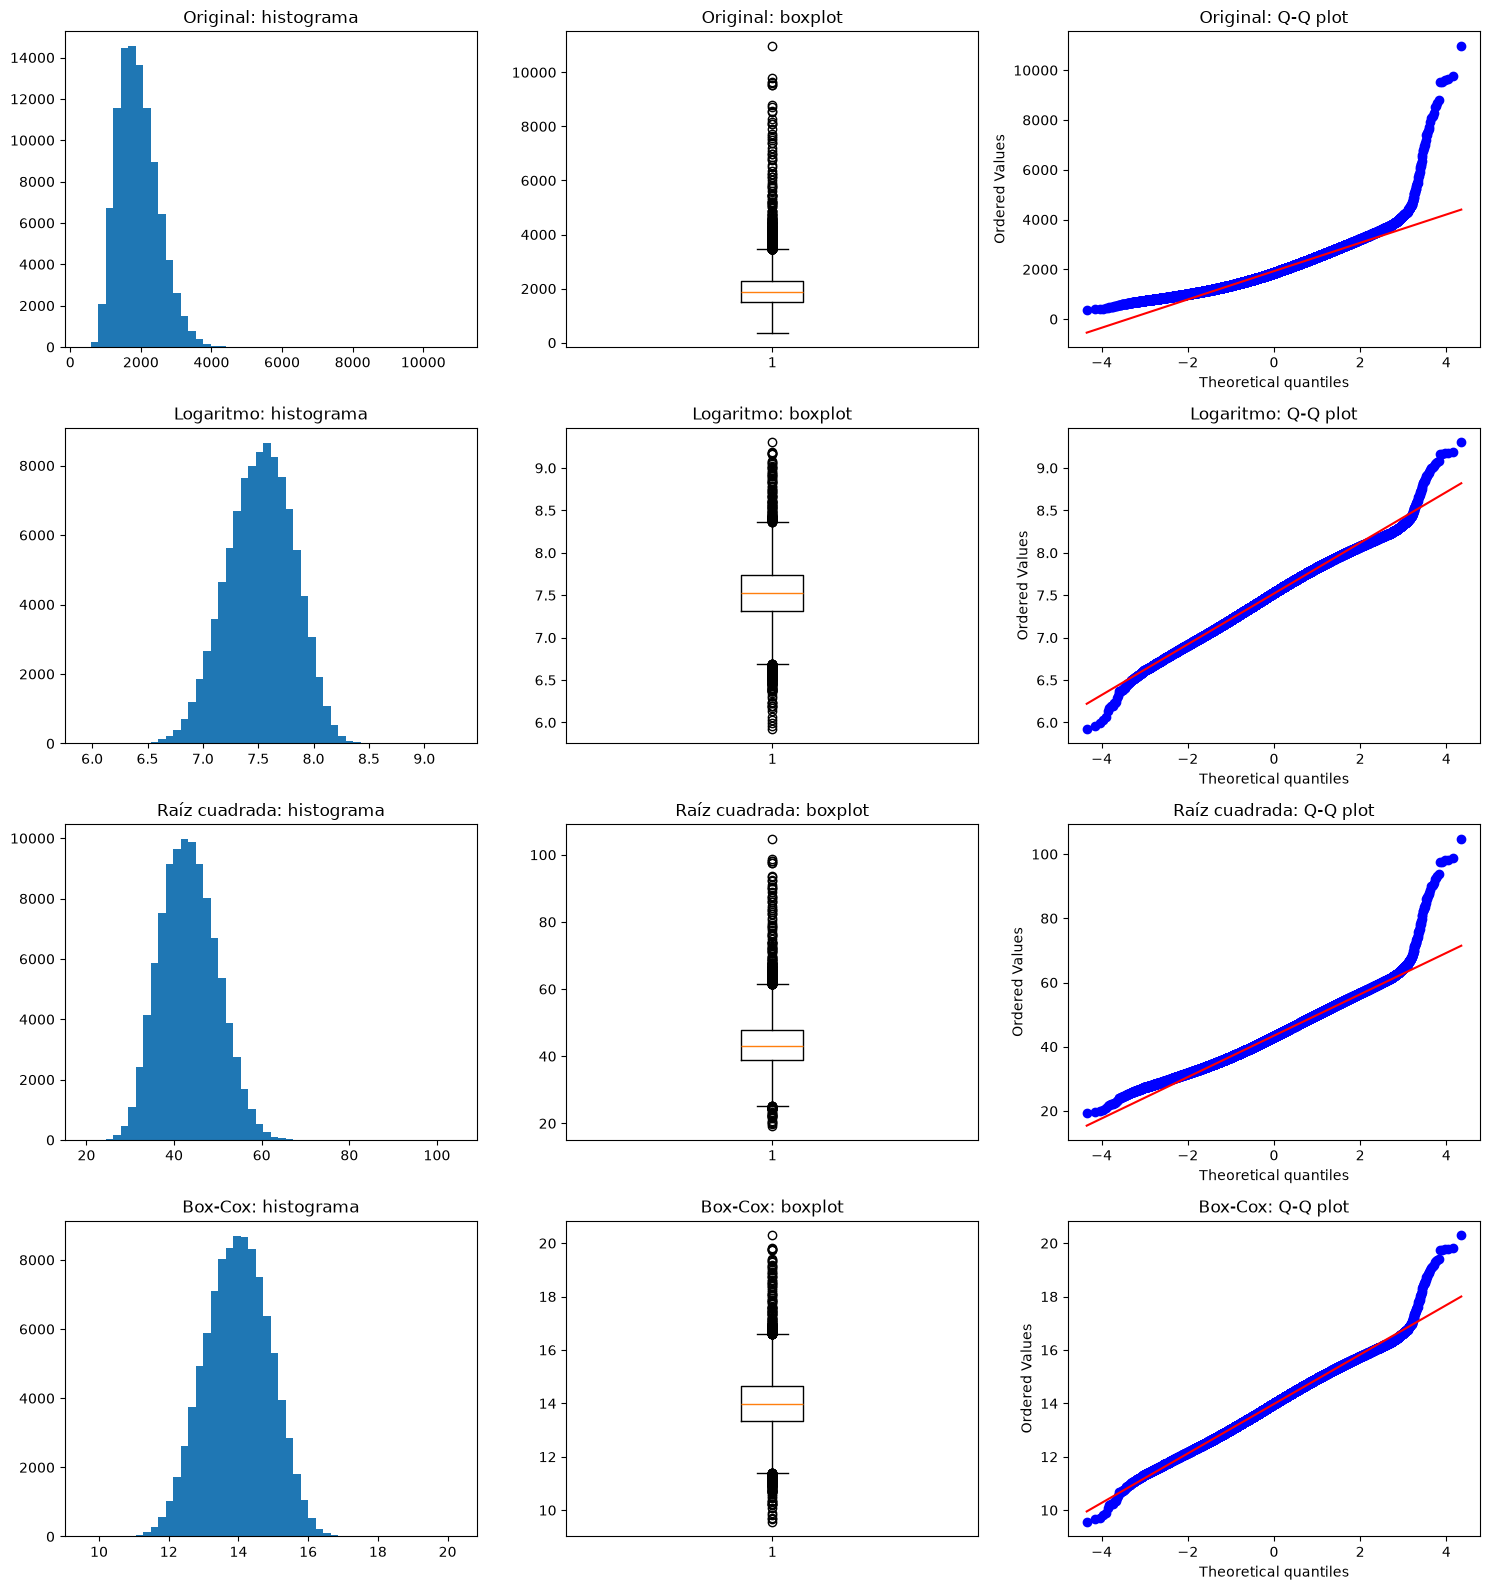

In [20]:
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for row, (name, x) in zip(axes, price_versions.items()):
    row[0].hist(x, bins=50)
    row[0].set_title(f"{name}: histograma")
    row[1].boxplot(x)
    row[1].set_title(f"{name}: boxplot")
    probplot(x, plot=row[2])
    row[2].set_title(f"{name}: Q-Q plot")
plt.tight_layout()
plt.show()

In [21]:
def count_outliers(x):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    return int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())

pd.DataFrame({name: {"skew": pd.Series(x).skew(), "outliers": count_outliers(x)}
              for name, x in price_versions.items()}).T

,skew,outliers
Original,0.986644,976.0
Logaritmo,-0.133105,386.0
Raíz cuadrada,0.332253,364.0
Box-Cox,-0.000238,317.0


In [22]:
cont_cols = ["weight_kg", "power_watts", "price"]
compu_transf[cont_cols] = boxcox_tr.fit_transform(compu_transf[cont_cols])

**Respuesta 6.** Comparación de las transformaciones de `price`:

| Transformación | Skew | Outliers |
|---|---|---|
| Original | 0.987 | 976 |
| Logaritmo | -0.133 | 386 |
| Raíz cuadrada | 0.332 | 364 |
| Box-Cox | -0.0002 | 317 |

La original tiene sesgo a la derecha, con una cola larga de valores atípicos en el boxplot y un Q-Q plot que se curva hacia arriba en el extremo derecho. La raíz cuadrada reduce el sesgo pero conserva una cola derecha. El logaritmo sobrecorrige: el sesgo pasa a ser negativo y aparece una cola izquierda de atípicos. **Box-Cox es la mejor**: su sesgo es el más cercano a 0, tiene la menor cantidad de outliers, su histograma es el más simétrico y su Q-Q plot es, a simple vista, el que mejor sigue la recta. Aun así conserva atípicos en ambos extremos y el Q-Q plot se separa de la recta en las colas, por lo que ninguna transformación elimina por completo los valores extremos. Se aplicó Box-Cox a `weight_kg`, `power_watts` y `price` (Box-Cox exige valores positivos, condición que cumplen las tres).

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [23]:
num_cols = compu_transf.select_dtypes(include="number").columns
compu_transf[num_cols] = MinMaxScaler().fit_transform(compu_transf[num_cols])
compu_transf[num_cols].agg(["min", "max"]).T

,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


**Respuesta 7.** `MinMaxScaler` se aplicó a las 12 columnas numéricas del dataframe, que se reemplazaron por sus versiones escaladas: la tabla muestra mínimo 0 y máximo 1 en todas.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [24]:
wifi_order = ["Wi-Fi 5", "Wi-Fi 6", "Wi-Fi 6E", "Wi-Fi 7"]
compu_transf[["wifi"]] = OrdinalEncoder(categories=[wifi_order]).fit_transform(compu_transf[["wifi"]])
compu_transf[["wifi"]] = MinMaxScaler().fit_transform(compu_transf[["wifi"]])
compu_transf["wifi"].value_counts().sort_index()

wifi
0.000000    19926
0.333333    46149
0.666667    25923
1.000000     8002
Name: count, dtype: int64

**Respuesta 8.** `wifi` se codificó con `OrdinalEncoder` indicando el orden Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7 (0, 1, 2 y 3) y después se escaló con `MinMaxScaler`, ambos sobre la misma columna, de modo que quedaron los valores 0, 0.333, 0.667 y 1 (con 19926, 46149, 25923 y 8002 observaciones, las mismas frecuencias que Wi-Fi 5, 6, 6E y 7 en la pregunta 2).

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [25]:
bin_df = BinaryEncoder(cols=["gpu_model"]).fit_transform(compu_transf[["gpu_model"]])
bin_df.head()

,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


**Respuesta 9.** `BinaryEncoder` representó las 49 categorías de `gpu_model` con solo **6 columnas** de ceros y unos (`gpu_model_0` a `gpu_model_5`), en lugar de las 49 que habría generado One-Hot Encoding. El resultado quedó en `bin_df`.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [26]:
ohe_cols = compu_transf.select_dtypes(exclude="number").columns.drop("gpu_model")
ohe = OneHotEncoder(drop="first", sparse_output=False).set_output(transform="pandas")
ohe_df = ohe.fit_transform(compu_transf[ohe_cols])
ohe_df.head()

,device_type_Laptop,brand_Acer,brand_Apple,brand_Dell,brand_Gigabyte,brand_HP,brand_Lenovo,brand_MSI,brand_Razer,brand_Samsung,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [27]:
compu_transf = pd.concat([compu_transf.drop(columns=[*ohe_cols, "gpu_model"]), bin_df, ohe_df], axis=1)
compu_transf.shape

(100000, 54)

In [28]:
compu_transf.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


**Respuesta 10.** `OneHotEncoder` con `drop="first"` codificó las 8 variables categóricas restantes (`device_type`, `brand`, `os`, `form_factor`, `cpu_brand`, `gpu_brand`, `storage_type` y `display_type`) en 35 columnas, guardadas en `ohe_df`. Después de eliminar las variables originales y concatenar `bin_df` y `ohe_df`, el dataframe tiene 100000 filas y 54 columnas. El `describe()` muestra mínimo 0 y máximo 1 en todas, y no aparecen las filas `unique`, `top` ni `freq`, propias de las columnas de texto: todas las variables son numéricas y están en la misma escala.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude Code (basado en Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis. https://claude.com/claude-code

---